In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense, Embedding, GlobalAveragePooling1D, GlobalMaxPooling1D, Conv1D, MaxPooling1D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

Q1

Load support_tickets.csv into a pandas DataFrame.

Drop any duplicate rows and
drop any rows with missing values.

Print the shape of the cleaned DataFrame.

Then split the data into
training (80%) and test (20%) sets using train_test_split with random_state=42 and stratify=the
label column (this keeps the ratio of class label 1 to class label 0 balanced across both sets).

Print the
number of urgent tickets (is_urgent equal to 1) versus routine tickets (is_urgent equal to 0) in the
training set.

In [3]:
dataset = pd.read_csv('/content/drive/MyDrive/AI - St. Thomas Summer 2026/support_tickets.csv')
dataset = dataset.drop_duplicates()
dataset = dataset.dropna()
print(dataset.shape)

(1988, 2)


In [4]:
x_train, x_test, y_train, y_test = train_test_split(dataset['ticket_text'], dataset['is_urgent'], test_size=0.2, random_state=42, stratify=dataset['is_urgent'])

In [5]:
print("Urgent versus routine tickets in training set:", y_train.value_counts())

Urgent versus routine tickets in training set: is_urgent
0    834
1    756
Name: count, dtype: int64


Q2

Create a Tokenizer with num_words=3000 and oov_token="< OOV>".

Fit the tokenizer on the training text only (fitting on the test set as well would leak information about test vocabulary into
your model).

Use the fitted tokenizer to convert both the training and test ticket text into integer sequences with texts_to_sequences, then pad or truncate every sequence to a length of 40 using
pad_sequences(..., maxlen=40, padding="post", truncating="post").

Print the length of the
tokenizer's word index (the full vocabulary found in training), and print the shapes of the padded
training and test arrays.


In [6]:
tokenizer = Tokenizer(num_words = 3000, oov_token="<OOV>")
tokenizer.fit_on_texts(x_train)

x_train_seq = tokenizer.texts_to_sequences(x_train)
x_test_seq = tokenizer.texts_to_sequences(x_test)

x_train_pad = pad_sequences(x_train_seq, maxlen=40, padding="post", truncating="post")
x_test_pad = pad_sequences(x_test_seq, maxlen=40, padding="post", truncating="post")

print("Length of tokenizer's word index:", len(tokenizer.word_index))
print("Shape of padded training array:", x_train_pad.shape)
print("Shape of padded test array:", x_test_pad.shape)

Length of tokenizer's word index: 322
Shape of padded training array: (1590, 40)
Shape of padded test array: (398, 40)


Q3

Build a baseline text classifier with the following architecture, in order:
Embedding(3000, 16), then GlobalAveragePooling1D(), then Dense(16, activation="relu"), then
Dense(1, activation="sigmoid").

Compile with loss="binary_crossentropy", optimizer="adam",
and metrics=["accuracy"].

Train for 15 epochs using validation_data=(X_test_pad, y_test).

Plot the training and validation accuracy on the same plot.

Print the final training accuracy and final validation accuracy as train_acc_q3 and val_acc_q3.

In [7]:
T = x_train_pad.shape[1]

In [8]:
tf.keras.utils.set_random_seed(42)

i = Input(shape=(T,))
x = Embedding(3000, 16)(i)
x = GlobalAveragePooling1D()(x)
x = Dense(16, activation='relu')(x)
x = Dense(1, activation='sigmoid')(x)

model = Model(i, x)

In [9]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [10]:
r = model.fit(x_train_pad, y_train, epochs=15, validation_data=(x_test_pad, y_test))

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7340 - loss: 0.6668 - val_accuracy: 0.8794 - val_loss: 0.6263
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9327 - loss: 0.5651 - val_accuracy: 0.9648 - val_loss: 0.4937
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9553 - loss: 0.4117 - val_accuracy: 0.9598 - val_loss: 0.3387
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9616 - loss: 0.2767 - val_accuracy: 0.9648 - val_loss: 0.2318
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9654 - loss: 0.2032 - val_accuracy: 0.9673 - val_loss: 0.1824
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9667 - loss: 0.1729 - val_accuracy: 0.9673 - val_loss: 0.1611
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9679 - loss: 0.1599 - val_accuracy: 0.9673 - val_loss: 0.1507
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9679 - loss: 0.1533 - val_accuracy: 0.9673 - val_loss

In [11]:
train_acc_q3 = r.history['accuracy'][-1]
val_acc_q3 = r.history['val_accuracy'][-1]

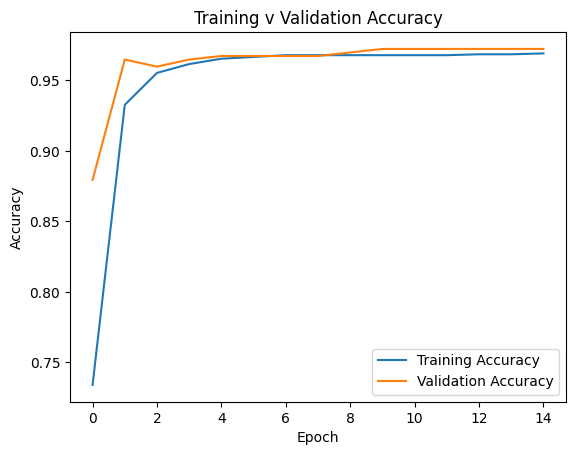

In [12]:
plt.plot(r.history['accuracy'], label='Training Accuracy')
plt.plot(r.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training v Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [13]:
print("Training Accuracy", train_acc_q3)
print("Validation Accuracy", val_acc_q3)

Training Accuracy 0.9691823720932007
Validation Accuracy 0.9723618030548096


Q4

Repeat Q3, but replace the GlobalAveragePooling1D model with a CNN architecture: Embedding(3000, 16), then Conv1D(32, 5, activation="relu"), then MaxPooling1D(2), then Conv1D(32, 5, activation="relu"), then GlobalMaxPooling1D(), then Dense(16,
activation="relu"), then Dense(1, activation="sigmoid").

Use the same compile settings, training
setup (15 epochs, same validation data), and plot as Q3.

Print train_acc_q4 and val_acc_q4, and
print the difference between val_acc_q4 and val_acc_q3

In [14]:
T = x_train_pad.shape[1]

In [15]:
tf.keras.utils.set_random_seed(42)

i = Input(shape=(T,))
x = Embedding(3000, 16)(i)
x = Conv1D(32, 5, activation='relu')(x)
x = MaxPooling1D(2)(x)
x = Conv1D(32, 5, activation='relu')(x)
x = GlobalMaxPooling1D()(x)
x = Dense(16, activation='relu')(x)
x = Dense(1, activation='sigmoid')(x)

model2 = Model(i, x)

In [16]:
model2.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [17]:
r2 = model2.fit(x_train_pad, y_train, epochs=15, validation_data=(x_test_pad, y_test))

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.8478 - loss: 0.5968 - val_accuracy: 0.9724 - val_loss: 0.3001
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9679 - loss: 0.1658 - val_accuracy: 0.9749 - val_loss: 0.1207
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9686 - loss: 0.1346 - val_accuracy: 0.9749 - val_loss: 0.1254
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9686 - loss: 0.1286 - val_accuracy: 0.9749 - val_loss: 0.1287
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9686 - loss: 0.1246 - val_accuracy: 0.9749 - val_loss: 0.1320
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9686 - loss: 0.1212 - val_accuracy: 0.9749 - val_loss: 0.1358
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9686 - loss: 0.1176 - val_accuracy: 0.9749 - val_loss: 0.1394
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9692 - loss: 0.1138 - val_accuracy: 0.9749 - val_loss

In [18]:
train_acc_q4 = r2.history['accuracy'][-1]
val_acc_q4 = r2.history['val_accuracy'][-1]

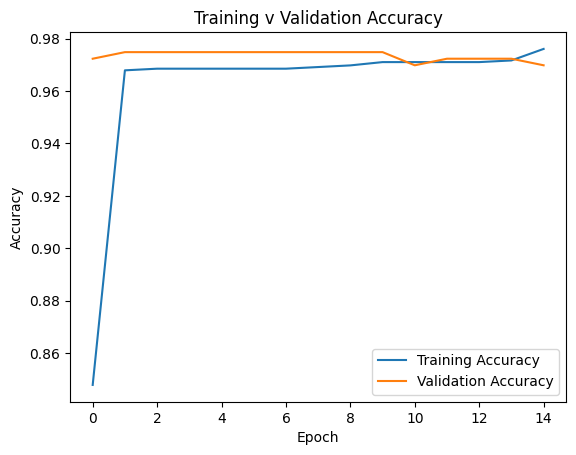

In [19]:
plt.plot(r2.history['accuracy'], label='Training Accuracy')
plt.plot(r2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training v Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [20]:
print("Training Accuracy", train_acc_q4)
print("Validation Accuracy", val_acc_q4)
print("Difference between Q4 and Q3 validation accuracy:", val_acc_q4 - val_acc_q3)

Training Accuracy 0.9761006236076355
Validation Accuracy 0.9698492288589478
Difference between Q4 and Q3 validation accuracy: -0.0025125741958618164


Q5

Repeat Q3 again, but this time use an LSTM architecture: Embedding(3000, 16), then LSTM(32), then Dense(16, activation="relu"), then Dense(1, activation="sigmoid").

Use the same compile settings, training setup, and plot as Q3.

Print train_acc_q5 and val_acc_q5, and print the difference between val_acc_q5 and val_acc_q3.

Then, using whichever of the three models (Q3, Q4, or Q5) had the highest validation accuracy, tokenize, pad, and predict on the following five new
ticket sentences (copy them exactly as written below):
1. "URGENT: the payment gateway is completely down and customers cannot check out
right now, please call me immediately."
2. "Hi there, just wondering if there's a way to change the app icon color, no rush at
all."
3. "Emergency: my account dashboard deleted all of my saved reports and I have a board
meeting in an hour."
4. "Quick question, does the export tool support PDF files? Not urgent, just curious."
5. "Zorblatt frobnicator widget thingamajig is acting weird but it's not a big deal,
take your time."


Print the predicted probability and the predicted label for each sentence: report urgent (class label 1)
when the predicted probability is 0.5 or higher, and routine (class label 0) when the predicted
probability is below 0.5. The fifth sentence is deliberately nonsensical and contains made up words.


After making your five predictions, separately call tokenizer.texts_to_sequences() on just that fifth
sentence and print the resulting list of integers.

Identify which integer corresponds to the < OOV> token
and state how many times it appears in that sequence. This illustrates how the tokenizer handles
words it has never seen before

In [21]:
T = x_train_pad.shape[1]

In [22]:
tf.keras.utils.set_random_seed(42)

i = Input(shape=(T,))
x = Embedding(3000, 16)(i)
x = LSTM(32)(x)
x = Dense(16, activation='relu')(x)
x = Dense(1, activation='sigmoid')(x)

model3 = Model(i, x)

In [23]:
model3.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [24]:
r3 = model3.fit(x_train_pad, y_train, epochs=15, validation_data=(x_test_pad, y_test))

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5176 - loss: 0.6894 - val_accuracy: 0.8090 - val_loss: 0.6342
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9572 - loss: 0.2461 - val_accuracy: 0.9749 - val_loss: 0.1183
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9679 - loss: 0.1429 - val_accuracy: 0.9749 - val_loss: 0.1180
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9679 - loss: 0.1423 - val_accuracy: 0.9749 - val_loss: 0.1182
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9673 - loss: 0.1431 - val_accuracy: 0.9724 - val_loss: 0.1224
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9686 - loss: 0.1395 - val_accuracy: 0.9698 - val_loss: 0.1252
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9623 - loss: 0.1536 - val_accuracy: 0.9673 - val_loss: 0.1363
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9679 - loss: 0.1402 - val_accuracy: 0.9749 - val

In [25]:
train_acc_q5 = r3.history['accuracy'][-1]
val_acc_q5 = r3.history['val_accuracy'][-1]

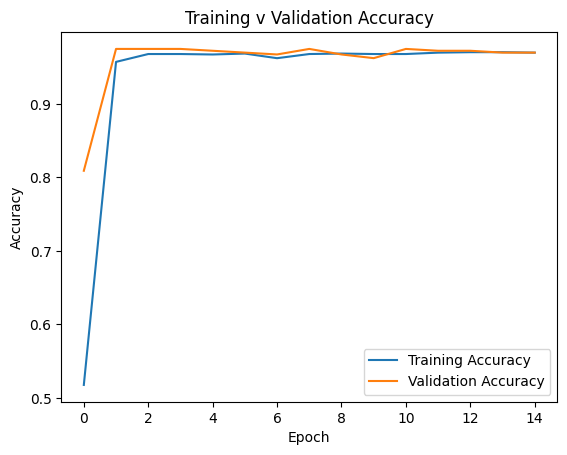

In [26]:
plt.plot(r3.history['accuracy'], label='Training Accuracy')
plt.plot(r3.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training v Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [27]:
print("Training Accuracy", train_acc_q5)
print("Validation Accuracy", val_acc_q5)
print("Difference between Q5 and Q3 validation accuracy:", val_acc_q5 - val_acc_q3)

Training Accuracy 0.9698113203048706
Validation Accuracy 0.9698492288589478
Difference between Q5 and Q3 validation accuracy: -0.0025125741958618164


In [28]:
#The first model from Q3 had the best validation accuracy and will be used below

text1 = ["URGENT: the payment gateway is completely down and customers cannot check out right now, please call me immediately."]
text2 = ["Hi there, just wondering if there's a way to change the app"]
text3 = ["Emergency: my account dashboard deleted all of my saved reports and I have a board meeting in an hour."]
text4 = ["Quick question, does the export tool support PDF files? Not urgent, just curious."]
text5 = ["Zorblatt frobnicator widget thingamajig is acting weird but it's not a big deal, take your time."]

text1_seq = tokenizer.texts_to_sequences(text1)
text1_pad = pad_sequences(text1_seq, maxlen=40, padding="post", truncating="post")

text2_seq = tokenizer.texts_to_sequences(text2)
text2_pad = pad_sequences(text2_seq, maxlen=40, padding="post", truncating="post")

text3_seq = tokenizer.texts_to_sequences(text3)
text3_pad = pad_sequences(text3_seq, maxlen=40, padding="post", truncating="post")

text4_seq = tokenizer.texts_to_sequences(text4)
text4_pad = pad_sequences(text4_seq, maxlen=40, padding="post", truncating="post")

text5_seq = tokenizer.texts_to_sequences(text5)
text5_pad = pad_sequences(text5_seq, maxlen=40, padding="post", truncating="post")

In [29]:
def classifier(pred):
  if pred >= 0.5:
    return "Urgent"
  else:
    return "Routine"

In [30]:
pred1 = model.predict(text1_pad)
print("Text 1 Predicted Probability:", pred1[0][0])
print("Text 1 Predicted Label:", classifier(pred1[0][0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step
Text 1 Predicted Probability: 0.97441363
Text 1 Predicted Label: Urgent


In [31]:
pred2 = model.predict(text2_pad)
print("Text 2 Predicted Probability:", pred2[0][0])
print("Text 2 Predicted Label:", classifier(pred2[0][0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
Text 2 Predicted Probability: 0.073461264
Text 2 Predicted Label: Routine


In [32]:
pred3 = model.predict(text3_pad)
print("Text 3 Predicted Probability:", pred3[0][0])
print("Text 3 Predicted Label:", classifier(pred3[0][0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Text 3 Predicted Probability: 0.930832
Text 3 Predicted Label: Urgent


In [33]:
pred4 = model.predict(text4_pad)
print("Text 4 Predicted Probability:", pred4[0][0])
print("Text 4 Predicted Label:", classifier(pred4[0][0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Text 4 Predicted Probability: 0.1774737
Text 4 Predicted Label: Routine


In [34]:
pred5 = model.predict(text5_pad)
print("Text 5 Predicted Probability:", pred5[0][0])
print("Text 5 Predicted Label:", classifier(pred5[0][0]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Text 5 Predicted Probability: 0.29237175
Text 5 Predicted Label: Routine


In [35]:
text5_seq = tokenizer.texts_to_sequences(text5)
print(text5_seq)

[[1, 1, 208, 1, 5, 1, 1, 33, 106, 81, 3, 80, 167, 96, 10, 46]]


In [36]:
word_index = tokenizer.word_index
print(word_index)

{'<OOV>': 1, 'the': 2, 'a': 3, 'this': 4, 'is': 5, 'to': 6, 'just': 7, 'for': 8, 'i': 9, 'your': 10, 'on': 11, 'my': 12, 'as': 13, 'me': 14, 'and': 15, 'you': 16, 'thanks': 17, 'wanted': 18, 'right': 19, 'about': 20, 'need': 21, 'help': 22, 'page': 23, 'has': 24, 'please': 25, 'confirmation': 26, 'can': 27, 'order': 28, 'seems': 29, 'app': 30, 'fine': 31, 'whenever': 32, 'but': 33, 'have': 34, 'what': 35, 'now': 36, 'works': 37, 'curious': 38, 'been': 39, 'immediately': 40, 'of': 41, 'let': 42, 'question': 43, 'urgent': 44, 'our': 45, 'time': 46, 'update': 47, 'small': 48, 'away': 49, 'soon': 50, 'possible': 51, 'like': 52, 'feature': 53, 'critical': 54, 'looking': 55, 'forward': 56, 'reply': 57, 'screen': 58, 'look': 59, 'know': 60, 'think': 61, "i'm": 62, 'in': 63, 'after': 64, 'be': 65, 'quick': 66, 'no': 67, 'affecting': 68, 'team': 69, 'billing': 70, 'email': 71, 'profile': 72, 'during': 73, 'at': 74, 'all': 75, 'well': 76, 'password': 77, 'reset': 78, 'account': 79, 'big': 80, 'n

In [37]:
# <OOV> = 1
unk_count = 0

for i in text5_seq[0]:
  if i == 1:
    unk_count += 1

print("The <OOV> token appears", unk_count, "times in the sequence")

The <OOV> token appears 5 times in the sequence
